# Final capstone: reproducible optimisation evidence

**Imperial College ML & AI — Stage 2, Component 25.3.** This notebook reproduces the main quantitative claims, with comments explaining each decision. It does **not** pretend to replay every historical optimisation decision.

**Inputs:** [279 recorded observations](../data/all_observations.csv), [final bests](../reports/current_best_after_week13.csv), and the project's Python modules.

**Scope:** verify provenance and counts; chart progress over 13 rounds; demonstrate a GP-based candidate suggestion without assigning an unobserved score; recover F8 using **only the original 40 observations** and check **13 later scores**; verify the permitted F5 boundary result.

The original HEBO-inspired and TuRBO-style code is [here](../src/bbo/optimizer.py). Full HEBO and BoTorch TuRBO-1 were added as **post-capstone research**, not used to generate these portal returns.

In [ ]:
# Make the notebook work when Jupyter starts in the repository root OR notebooks/.
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

cwd = Path.cwd().resolve()
ROOT = next((p for p in [cwd, *cwd.parents] if (p / 'data/all_observations.csv').exists()), None)
if ROOT is None:
    raise FileNotFoundError("Clone the repository and open the notebook from inside it.")
sys.path.insert(0, str(ROOT / 'src'))

from bbo.structural_validation import recover_f8, f5_at
from bbo.surrogates import fit_gp, inverse_mean
from bbo.acquisition import expected_improvement
from bbo.search import sobol_points, portal_string

print("Repository folder:", ROOT.name)

## 1. Dataset and missing values

I start with the exact historical observations, not model-generated guesses. The programme supplied 175 starting points, followed by my 104 returned portal queries. One returned F7 score from Round 11 has no retained input vector, so it remains included in performance counts but is not used for fitting or spatial plots.

In [2]:
observations = pd.read_csv(ROOT / 'data/all_observations.csv')
required = {'function', 'round', 'source', 'input_status', 'output'}
assert required.issubset(observations.columns)
assert len(observations) == 279
assert (observations['source'] == 'course_initial').sum() == 175
assert (observations['source'] == 'personal_portal').sum() == 104
assert observations['output'].notna().all()

missing = observations.loc[observations['input_status'] == 'missing_input']
assert len(missing) == 1
assert int(missing.iloc[0]['function']) == 7 and int(missing.iloc[0]['round']) == 11
assert missing.iloc[0][[f'x{i}' for i in range(1, 7)]].isna().all()

display(pd.DataFrame({
    'Dataset': ['Course initial', 'Personal portal', 'Total', 'Rows with missing input'],
    'Records': [175, 104, len(observations), len(missing)]
}))
display(observations.groupby('function', as_index=False)['output'].agg(['count','max']))

,Dataset,Records
0,Course initial,175
1,Personal portal,104
2,Total,279
3,Rows with missing input,1


,function,count,max
0,1,23,2.000000
1,2,23,0.744250
2,3,28,-0.003753
3,4,43,0.746898
4,5,33,8662.405001
5,6,33,-0.037519
6,7,43,3.322368
7,8,53,10.000000


## 2. Verify the final bests

A final result must be the **largest observed return** for that function, not the latest return or a GP prediction. I recompute all eight maxima from the complete record and compare them with the published results table.

In [3]:
published = pd.read_csv(ROOT / 'reports/current_best_after_week13.csv')
computed = observations.groupby('function')['output'].max().sort_index()
stored = published.set_index('Function')['Final_Best'].sort_index()
np.testing.assert_allclose(computed.to_numpy(), stored.to_numpy(), atol=1e-12, rtol=1e-12)

view = published[['Function', 'Final_Best', 'First_Achieved_Round', 'Best_Input']]
display(view)
print("All eight final bests reproduce exactly within floating-point tolerance.")

,Function,Final_Best,First_Achieved_Round,Best_Input
0,1,2.000000,11,0.628540-0.628540
1,2,0.744250,13,0.864900-0.500000
2,3,-0.003753,13,0.197280-0.523429-0.470094
3,4,0.746898,13,0.416903-0.415704-0.360320-0.415205
4,5,8662.405001,10,0.999999-0.999999-0.999999-0.999999
5,6,-0.037519,12,0.415080-0.344119-0.644062-0.776818-0.076258
6,7,3.322368,12,0.201689-0.150011-0.476874-0.275332-0.311652-0...
7,8,10.000000,10,0.100000-0.150000-0.130000-0.150000-0.800000-0...


All eight final bests reproduce exactly within floating-point tolerance.


## 3. Progress through thirteen rounds

For every function I take the best output of each round and calculate its cumulative maximum. Each subplot has its **own y-axis scale**: scores across different functions cannot be added or compared directly.

The first round in this notebook is `round=0`, representing the programme's starting data. The remaining 13 rounds are my returned queries.

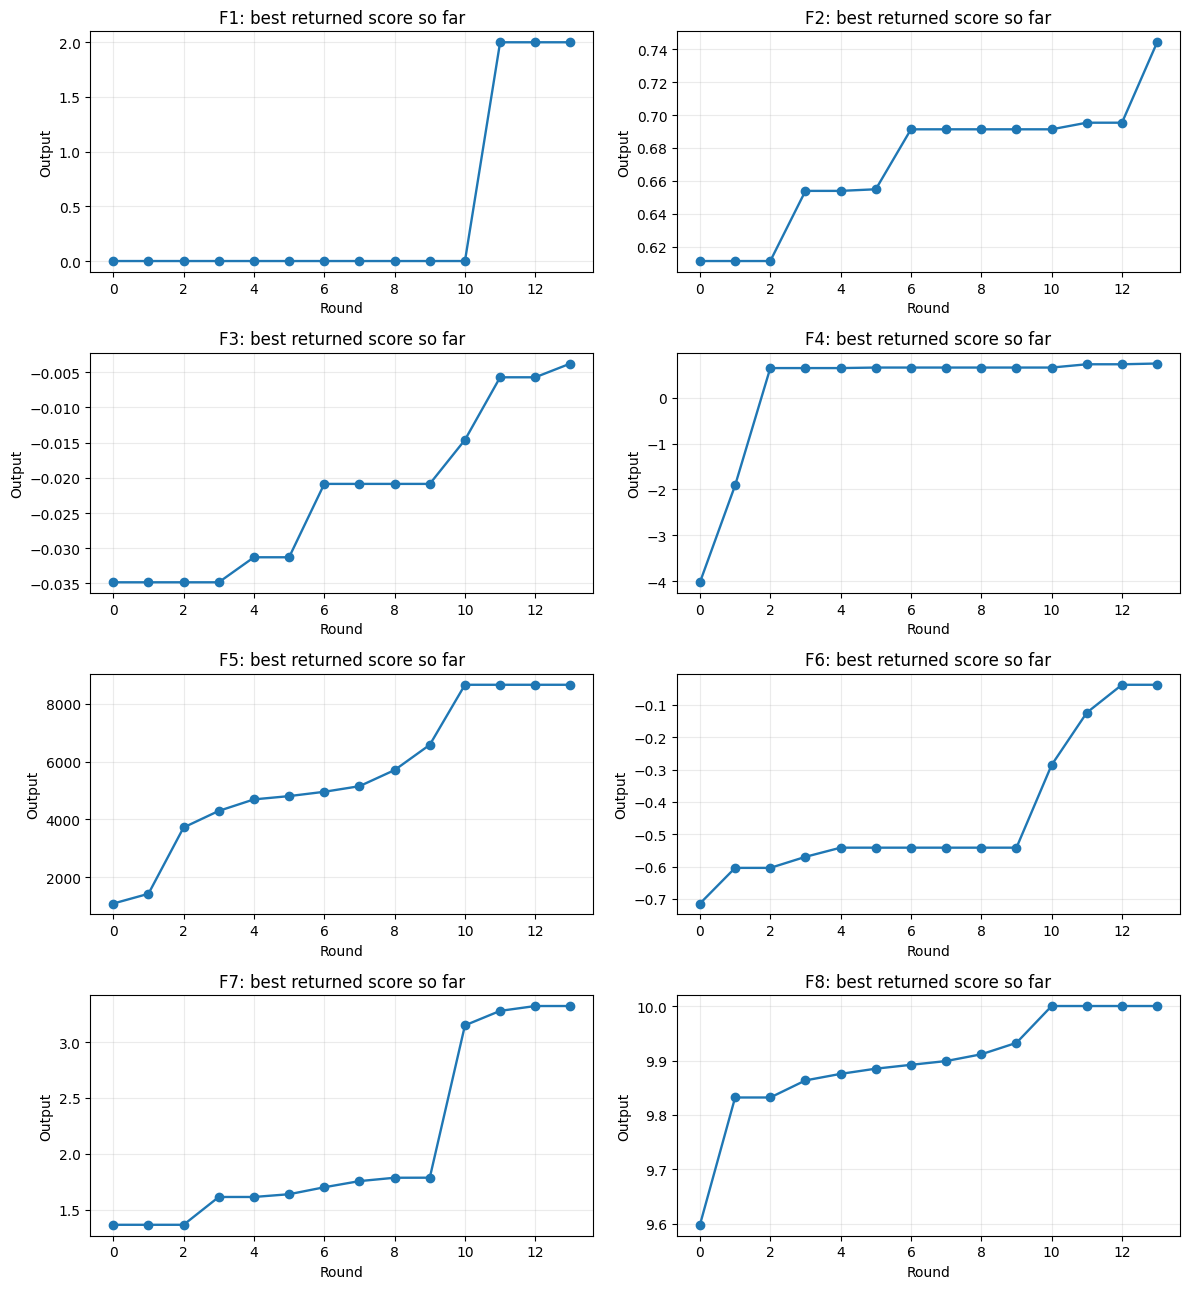

In [4]:
fig, axes = plt.subplots(4, 2, figsize=(12, 13))
for function_id, axis in zip(range(1, 9), axes.flat):
    records = observations.loc[observations['function'] == function_id]
    best_by_round = records.groupby('round')['output'].max().sort_index().cummax()
    axis.plot(best_by_round.index, best_by_round.to_numpy(), marker='o', linewidth=1.7)
    axis.set(title=f'F{function_id}: best returned score so far', xlabel='Round', ylabel='Output')
    axis.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## 4. Illustrative Gaussian Process decision

This is a **separate retrospective example**, not a reconstruction of the exact candidate chosen in the course. I use F2's observations available **through Round 9**. A Matérn 2.5 GP, fitted with a Yeo–Johnson response transformation, predicts scores and uncertainty across a Sobol candidate pool. Expected Improvement (EI) balances predicted gains and uncertainty.

The algorithm proposes an input only. Without querying the real portal at that exact input, **its true score is unknown**.

In [ ]:
history_f2 = observations.loc[(observations['function'] == 2) & (observations['round'] <= 9)]
X = history_f2[['x1', 'x2']].to_numpy(float)
y = history_f2['output'].to_numpy(float)

# No later observations are available to this illustrative Week 9 decision.
model, transform, transformed_y = fit_gp(
    X, y, kernel='Matern25', transform='yeo-johnson', seed=25, restarts=0
)
pool = sobol_points(d=2, n_power=9, seed=25)
mu, sd = model.predict(pool, return_std=True)
ei = expected_improvement(mu, sd, float(transformed_y.max()))
winner = int(np.argmax(ei))
proposal = pool[winner]
predicted_raw_scale = float(inverse_mean([mu[winner]], transform)[0])

print('Best returned F2 score available through R9:', round(float(y.max()), 6))
print('Illustrative, unsubmitted candidate:', portal_string(proposal))
print('GP prediction (inverse-transformed location):', round(predicted_raw_scale, 6))
print('Predicted uncertainty on transformed scale:', round(float(sd[winner]), 6))
print('True portal score: UNKNOWN (not measured)')

**Interpreting the demonstration.** In this reproducible example, EI selects approximately `0.972783-0.012074`, with a modelled score around **0.427**, below F2's best observed score of roughly **0.69** at the historical cutoff. EI can still value that point because its uncertainty is high: this is an **exploration proposal**, not a guarantee of improvement. It was not one of my submitted portal queries, and I would check its expected information value and the remaining evaluation budget before following it.

## 4A. Forecast errors: where the model was reliable, and where it was not

The Week 9 audit retains pre-result forecasts and their actual portal returns. The chart plots the **absolute prediction error** for each function with a recorded forecast, on a **logarithmic axis**. This lets us see both F2's miss (about 0.225) and F4's exceptionally small error (about 1.6 × 10⁻⁹), even though F5 has much larger raw scores.

Unrecorded forecasts are excluded. Because the functions have different output scales, the graph illustrates **calibration within each function**, not a single cross-function accuracy ranking.

In [ ]:
audit = pd.read_csv(ROOT / 'reports/week9_forecast_audit.csv')
paired = audit.dropna(subset=['Pre_result_forecast', 'Actual', 'Absolute_error']).copy()
assert len(paired) >= 4
assert (paired['Absolute_error'] > 0).all()

# Raw scores have radically different scales: F5 is measured in thousands,
# while F4's forecast error is about one billionth. A logarithmic error axis
# makes the relative order-of-magnitude differences visible without
# pretending that the objectives themselves share a common scale.
paired = paired.sort_values('Absolute_error', ascending=False)
labels = [f"F{int(f)}" for f in paired['Function']]
errors = paired['Absolute_error'].to_numpy(float)

fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.bar(labels, errors, width=0.65)
ax.set_yscale('log')
ax.set_ylim(errors.min() / 5, errors.max() * 5)
for bar, value in zip(bars, errors):
    ax.annotate(f"{value:.2g}", (bar.get_x() + bar.get_width()/2, value),
                xytext=(0, 5), textcoords='offset points',
                ha='center', va='bottom', fontsize=9)
ax.set(xlabel='Function', ylabel='Absolute forecast error (logarithmic scale)',
       title='Week 9 forecast errors: F2 miss versus F4 precision')
ax.grid(axis='y', which='both', alpha=0.25)
plt.tight_layout()
plt.show()

display(paired[['Function', 'Pre_result_forecast', 'Actual', 'Absolute_error']].sort_values('Function'))
print('These are historical recorded forecasts, not scores for unqueried model proposals.')
print('Different functions have different output scales; this is not a fair cross-function performance ranking.')

## 5. F8: test a simple structural model against later evidence

F8's model is an **additive quadratic with 17 coefficients**. The fitting routine uses the **40 course-provided points only**, then predicts the next **13 personal portal outputs** without fitting to them.

This test was conducted retrospectively after the capstone. It demonstrates that a simple equation already fitted the initial evidence exceptionally well; it does not claim I had identified it in Round 1.

In [7]:
f8 = recover_f8(ROOT)
assert f8['rank'] == 17
assert f8['initial_count'] == 40 and f8['holdout_count'] == 13
assert f8['max_holdout_error'] < 2e-14
assert abs(f8['maximum'] - 10) < 1e-12

print('Full-rank coefficients:', f8['rank'])
print('Fitted optimum coordinates:', np.round(f8['centre'], 6))
print('Fitted optimum score:', round(f8['maximum'], 12))
print('Maximum absolute prediction error on 13 later returns:',
      f"{f8['max_holdout_error']:.3e}")
print('Curvature ratio, x3 to x8:', f8['weights'][2] / f8['weights'][7])

Full-rank coefficients: 17
Fitted optimum coordinates: [0.1  0.15 0.13 0.15 0.8  0.5  0.2  0.6 ]
Fitted optimum score: 10.0
Maximum absolute prediction error on 13 later returns: 1.599e-14
Curvature ratio, x3 to x8: 30.000000000006345


### Visualise the F8 equation

Because F8 has **eight inputs**, this plot shows a **two-input slice**, not the entire function. Only x3 and x8 vary; all six remaining values stay at the fitted optimum. This makes their different curvature weights visible.

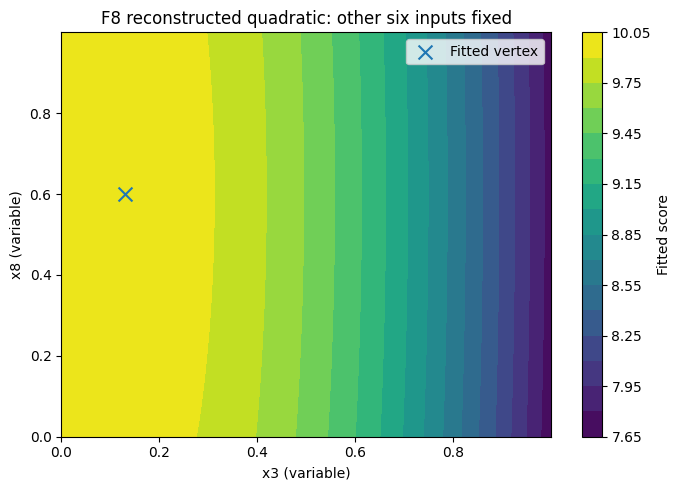

In [8]:
xs = np.linspace(0, .999999, 100)
x3, x8 = np.meshgrid(xs, xs)
# The additive model is f(x) = peak - sum(weight_j * (x_j - centre_j)**2).
# Fixing the other six coordinates at centre makes their squared terms zero.
surface = (f8['maximum']
           - f8['weights'][2] * (x3 - f8['centre'][2])**2
           - f8['weights'][7] * (x8 - f8['centre'][7])**2)

fig, ax = plt.subplots(figsize=(7, 5))
contours = ax.contourf(x3, x8, surface, levels=22)
ax.scatter([f8['centre'][2]], [f8['centre'][7]], marker='x', s=100, label='Fitted vertex')
ax.set(xlabel='x3 (variable)', ylabel='x8 (variable)',
       title='F8 reconstructed quadratic: other six inputs fixed')
ax.legend()
fig.colorbar(contours, ax=ax, label='Fitted score')
plt.tight_layout()
plt.show()

### F8 input sensitivity: eight one-variable curves

The two-dimensional contour above shows only x3 and x8. To make the whole eight-input additive formula easier to interpret, these eight plots vary **one input at a time**, while the other seven stay fixed at the fitted optimum. The plots share the **same vertical scale**, so the differing curvature is directly comparable between inputs.

In [ ]:
fig, axs = plt.subplots(2, 4, figsize=(14, 6), sharex=True, sharey=True)
grid = np.linspace(0, .999999, 121)
for j, ax in enumerate(axs.flat):
    values = f8['maximum'] - f8['weights'][j] * (grid - f8['centre'][j])**2
    ax.plot(grid, values)
    ax.axvline(f8['centre'][j], linestyle='--', linewidth=1)
    ax.set(title=f"x{j+1}, weight={f8['weights'][j]:g}", xlabel=f"x{j+1}", ylabel='Modelled score')
    ax.grid(alpha=.2)
plt.suptitle('F8: change one input, hold the other seven at the fitted optimum', y=1.02)
plt.tight_layout()
plt.show()

## 6. F5: check the legal boundary

The reconstructed F5 power-sum equation was identified **after** my successful Round 10 boundary query. The portal's legal maximum coordinate was **0.999999**, not 1.000000. This check ensures the comparison uses the actual permitted setting, avoiding a misleading mathematical corner value.

In [10]:
legal_corner = np.full(4, 0.999999)
f5_model = f5_at(legal_corner)
f5_portal = 8662.405001248297
assert abs(f5_model - f5_portal) < 1e-9
print('Permitted input:', [float(x) for x in legal_corner])
print('Reconstructed value:', f"{f5_model:.12f}")
print('Confirmed portal value:', f"{f5_portal:.12f}")

Permitted input: [0.999999, 0.999999, 0.999999, 0.999999]
Reconstructed value: 8662.405001248297
Confirmed portal value: 8662.405001248297


## 7. Limits and next steps

The plots and verified values establish **what was observed**. They do not prove global optima for unresolved functions or recreate unrecorded pre-submission forecasts. F2/F3/F4/F6 have no verified complete equation, F1's full historical plotting parameters are not retained, and the R11 F7 input remains unavailable.

The historical HEBO-inspired and TuRBO-style code is discussed in [the algorithm guide](../docs/optimisation_algorithms.md). Separate *post-capstone* full implementations are in [benchmarks](../benchmarks/full_optimisers/README.md); any F8 scores generated by those engines are **model simulations**, not portal outcomes.

**To reproduce:** install [the notebook dependencies](../requirements-notebook.txt), then use **Run All**. The CI workflow executes this notebook on a clean machine and publishes the executed notebook as an artifact. Refer to the [datasheet](../DATASHEET.md), [model card](../MODEL_CARD.md) and [assessment checklist](../docs/assessment_25_3.md) for evidence and limitations.